In [1]:
import os
import pandas as pd 

In [2]:
import yaml
input_file = r"C:\Users\jana\OneDrive\Documents\project_2_DD\data"
output_folder = r"C:\Users\jana\OneDrive\Documents\project_2_DD\stock_csv"
os.makedirs(output_folder, exist_ok=True)



In [3]:
stock_data = {}

In [4]:
for root, dirs, files in os.walk(input_file):

    for file in files:

        file_path = os.path.join(root, file)

        with open(file_path, "r") as f:
            data = yaml.safe_load(f)

            for stock in data:

                ticker = stock["Ticker"]

                if ticker not in stock_data:
                    stock_data[ticker] = []

                stock_data[ticker].append(stock)


# எல்லா YAML files-ம் முடிந்த பிறகுதான் இந்த loop
for ticker, records in stock_data.items():

    df = pd.DataFrame(records)

    csv_path = os.path.join(
        output_folder,
        f"{ticker}.csv"
    )

    df.to_csv(csv_path, index=False)

In [5]:
print("Total stocks:", len(stock_data))

Total stocks: 50


In [6]:
sbin = pd.read_csv(r"C:\Users\jana\OneDrive\Documents\project_2_DD\stock_csv\SBIN.csv")
sbin

,Ticker,close,date,high,low,month,open,volume
0,SBIN,602.95,2023-10-03 05:30:00,604.90,589.60,2023-10,596.60,15322196
1,SBIN,586.25,2023-10-04 05:30:00,600.45,584.45,2023-10,600.00,24914612
2,SBIN,592.15,2023-10-05 05:30:00,594.35,587.10,2023-10,590.00,13248028
3,SBIN,594.25,2023-10-06 05:30:00,598.95,592.20,2023-10,593.40,8216780
4,SBIN,585.10,2023-10-09 05:30:00,589.00,581.55,2023-10,588.00,9189597
...,...,...,...,...,...,...,...,...
279,SBIN,804.25,2024-11-14 05:30:00,818.00,801.05,2024-11,808.65,9461484
280,SBIN,814.30,2024-11-18 05:30:00,816.70,799.25,2024-11,811.00,9322451
281,SBIN,803.00,2024-11-19 05:30:00,820.30,800.10,2024-11,819.00,13677029
282,SBIN,780.75,2024-11-21 05:30:00,798.50,761.55,2024-11,798.50,29486577


In [7]:
sbin.shape

(284, 8)

In [8]:
sbin.head()

,Ticker,close,date,high,low,month,open,volume
0,SBIN,602.95,2023-10-03 05:30:00,604.90,589.60,2023-10,596.6,15322196
1,SBIN,586.25,2023-10-04 05:30:00,600.45,584.45,2023-10,600.0,24914612
2,SBIN,592.15,2023-10-05 05:30:00,594.35,587.10,2023-10,590.0,13248028
3,SBIN,594.25,2023-10-06 05:30:00,598.95,592.20,2023-10,593.4,8216780
4,SBIN,585.10,2023-10-09 05:30:00,589.00,581.55,2023-10,588.0,9189597


In [9]:
sbin.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284 entries, 0 to 283
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Ticker  284 non-null    object 
 1   close   284 non-null    float64
 2   date    284 non-null    object 
 3   high    284 non-null    float64
 4   low     284 non-null    float64
 5   month   284 non-null    object 
 6   open    284 non-null    float64
 7   volume  284 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 17.9+ KB


In [10]:
sbin.describe()

,close,high,low,open,volume
count,284.000000,284.000000,284.000000,284.000000,2.840000e+02
mean,742.374472,750.332570,734.485211,742.892254,1.740825e+07
std,99.960548,101.686897,98.344345,100.292184,1.116115e+07
min,547.000000,552.900000,543.200000,550.000000,9.604530e+05
25%,640.400000,647.725000,633.925000,640.000000,1.166562e+07
50%,781.575000,790.100000,770.375000,783.800000,1.483907e+07
75%,819.900000,826.575000,813.125000,821.000000,1.973791e+07
max,905.650000,912.000000,883.300000,897.000000,1.223812e+08


In [11]:
sbin.isna().sum()

Ticker    0
close     0
date      0
high      0
low       0
month     0
open      0
volume    0
dtype: int64

In [12]:
sbin.duplicated().sum()

np.int64(0)

In [13]:
sbin['date'] = pd.to_datetime(sbin['date'])
sbin.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284 entries, 0 to 283
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Ticker  284 non-null    object        
 1   close   284 non-null    float64       
 2   date    284 non-null    datetime64[ns]
 3   high    284 non-null    float64       
 4   low     284 non-null    float64       
 5   month   284 non-null    object        
 6   open    284 non-null    float64       
 7   volume  284 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(1), object(2)
memory usage: 17.9+ KB


In [14]:
sbin['date'].is_monotonic_increasing

True

In [15]:
sbin[sbin['open'] < sbin['low']] 

,Ticker,close,date,high,low,month,open,volume


In [16]:
sbin[sbin['close'] < sbin['low']] 

,Ticker,close,date,high,low,month,open,volume


In [17]:
sbin[sbin['close'] > sbin['high']] 

,Ticker,close,date,high,low,month,open,volume


In [18]:
sbin[sbin['volume'] < 0]

,Ticker,close,date,high,low,month,open,volume


In [19]:
Q1 = sbin['volume'].quantile(0.25)
Q3 = sbin['volume'].quantile(0.75)
Q1


np.float64(11665620.0)

In [20]:
Q3

np.float64(19737911.0)

In [21]:
IQR = Q3 - Q1

In [22]:
IQR

np.float64(8072291.0)

In [23]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

In [24]:
lower_bound

np.float64(-442816.5)

In [25]:
upper_bound


np.float64(31846347.5)

In [26]:
sbin[sbin['volume'] > upper_bound].shape

(16, 8)

In [27]:
outlier_columns = ['open','close','high','low']
for column in outlier_columns:
    q1 = sbin[column].quantile(0.25)
    q3 = sbin[column].quantile(0.75)
    iqr = q3-q1
    lower_b = q1 - (1.5*iqr)
    upper_b = q3 + (1.5*iqr)
    outlier =  (sbin[column] < lower_b) | (sbin[column] > upper_b)
    outlier = (sbin[column] < lower_b) | (sbin[column] > upper_b)
    print(column, ":", outlier.sum())
        

open : 0
close : 0
high : 0
low : 0


In [28]:
folder_path = r"C:\Users\jana\OneDrive\Documents\project_2_DD\stock_csv"
files_list = os.listdir(folder_path)
len(files_list)

50

In [29]:
for files_name in files_list:
    files_path = os.path.join(folder_path,files_name)
    stock_df = pd.read_csv(files_path)
    missing = stock_df.isna().sum()
    if missing.sum() > 0 :
        print("\n",files_name)
        print(missing) 

In [30]:
cleaned_folder = r"C:\Users\jana\OneDrive\Documents\project_2_DD\cleaned_stock_csv"

os.makedirs(cleaned_folder, exist_ok=True)

In [31]:
for files_name in files_list:

    files_path = os.path.join(folder_path, files_name)
    stock_df = pd.read_csv(files_path)

    # Date datatype
    stock_df["date"] = pd.to_datetime(stock_df["date"])

    # Remove exact duplicates, if any
    stock_df = stock_df.drop_duplicates()

    # Arrange by date
    stock_df = stock_df.sort_values("date").reset_index(drop=True)

    # Save cleaned CSV
    cleaned_file_path = os.path.join(cleaned_folder, files_name)
    stock_df.to_csv(cleaned_file_path, index=False)

print("Cleaning completed")

Cleaning completed


In [32]:
cleaned_files = os.listdir(cleaned_folder)
print(len(cleaned_files))

50


In [33]:
for files_name in cleaned_files:
    files_path = os.path.join(cleaned_folder, files_name)

    stock_df = pd.read_csv(files_path)

    stock_df["daily_return"] = stock_df["close"].pct_change()

    stock_df.to_csv(files_path, index=False)

print("Daily return added to all 50 stocks")
    

Daily return added to all 50 stocks


In [34]:
yearly_returns =[]

In [35]:
for files_name in cleaned_files:
    files_path = os.path.join(cleaned_folder, files_name)

    stock_df = pd.read_csv(files_path)

    first_close = stock_df["close"].iloc[0]
    last_close = stock_df["close"].iloc[-1]

    yearly_return = (last_close - first_close) / first_close

    yearly_returns.append({
        "Ticker": stock_df["Ticker"].iloc[0],
        "Yearly_Return": yearly_return
    })

In [36]:
yearly_returns_df = pd.DataFrame(yearly_returns)


In [37]:
top_10_greenstocks = yearly_returns_df.sort_values("Yearly_Return",ascending=False)

In [38]:
top_10_greenstocks

,Ticker,Yearly_Return
47,TRENT,2.230926
8,BEL,1.017601
30,M&M,0.959770
5,BAJAJ-AUTO,0.890112
9,BHARTIARTL,0.695990
35,POWERGRID,0.688549
10,BPCL,0.674772
20,HEROMOTOCO,0.589767
40,SUNPHARMA,0.572824
17,HCLTECH,0.532574


In [39]:
# ============================================================
# 1. TOP 10 GREEN STOCKS
# ============================================================

top_10_greenstocks = yearly_returns_df.sort_values(
    "Yearly_Return",
    ascending=False
).head(10).reset_index(drop=True)

print("TOP 10 GREEN STOCKS")
print(top_10_greenstocks)


# ============================================================
# 2. BOTTOM 10 STOCKS
# ============================================================

bottom_10_lossstocks = yearly_returns_df.sort_values(
    "Yearly_Return",
    ascending=True
).head(10).reset_index(drop=True)

print("\nBOTTOM 10 STOCKS")
print(bottom_10_lossstocks)


# ============================================================
# 3. MARKET SUMMARY
# Green Stocks / Red Stocks
# ============================================================

green_stocks = yearly_returns_df[
    yearly_returns_df["Yearly_Return"] > 0
]

red_stocks = yearly_returns_df[
    yearly_returns_df["Yearly_Return"] < 0
]

green_count = len(green_stocks)
red_count = len(red_stocks)

print("\nMARKET SUMMARY")
print("Green Stocks:", green_count)
print("Red Stocks:", red_count)


# ============================================================
# 4. COMBINE ALL 50 CLEANED STOCK FILES
# ============================================================

all_stocks = []

for files_name in cleaned_files:

    files_path = os.path.join(cleaned_folder, files_name)

    stock_df = pd.read_csv(files_path)

    stock_df["date"] = pd.to_datetime(stock_df["date"])

    all_stocks.append(stock_df)

combined_df = pd.concat(
    all_stocks,
    ignore_index=True
)

print("\nCombined Data Shape:", combined_df.shape)


# ============================================================
# 5. AVERAGE PRICE AND AVERAGE VOLUME
# Here Close price is used as the stock price
# ============================================================

average_price = combined_df["close"].mean()

average_volume = combined_df["volume"].mean()

print("\nAverage Price:", average_price)
print("Average Volume:", average_volume)


# ============================================================
# 6. VOLATILITY OF ALL STOCKS
# Standard deviation of Daily Return
# ============================================================

volatility_data = []

for files_name in cleaned_files:

    files_path = os.path.join(cleaned_folder, files_name)

    stock_df = pd.read_csv(files_path)

    # Calculate daily return if it is not already available
    if "daily_return" not in stock_df.columns:
        stock_df["daily_return"] = stock_df["close"].pct_change()

    volatility = stock_df["daily_return"].std()

    volatility_data.append({
        "Ticker": stock_df["Ticker"].iloc[0],
        "Volatility": volatility
    })


volatility_df = pd.DataFrame(volatility_data)


# ============================================================
# 7. TOP 10 HIGHLY VOLATILE STOCKS
# ============================================================

top_10_volatile = volatility_df.sort_values(
    "Volatility",
    ascending=False
).head(10).reset_index(drop=True)

print("\nTOP 10 HIGHLY VOLATILE STOCKS")
print(top_10_volatile)


# ============================================================
# 8. CUMULATIVE RETURN FOR ALL STOCKS
# ============================================================

cumulative_data = []

for files_name in cleaned_files:

    files_path = os.path.join(cleaned_folder, files_name)

    stock_df = pd.read_csv(files_path)

    stock_df["date"] = pd.to_datetime(stock_df["date"])

    stock_df = stock_df.sort_values(
        "date"
    ).reset_index(drop=True)

    if "daily_return" not in stock_df.columns:
        stock_df["daily_return"] = stock_df["close"].pct_change()

    stock_df["cumulative_return"] = (
        1 + stock_df["daily_return"].fillna(0)
    ).cumprod() - 1

    cumulative_data.append(stock_df)


cumulative_df = pd.concat(
    cumulative_data,
    ignore_index=True
)


# ============================================================
# 9. FINAL CUMULATIVE RETURN OF EACH STOCK
# ============================================================

final_cumulative_returns = (
    cumulative_df
    .sort_values("date")
    .groupby("Ticker")
    .tail(1)[["Ticker", "cumulative_return"]]
    .reset_index(drop=True)
)


# ============================================================
# 10. TOP 5 CUMULATIVE PERFORMERS
# ============================================================

top_5_cumulative = final_cumulative_returns.sort_values(
    "cumulative_return",
    ascending=False
).head(5).reset_index(drop=True)

print("\nTOP 5 CUMULATIVE PERFORMERS")
print(top_5_cumulative)


# ============================================================
# 11. CORRELATION MATRIX
# Close prices of all stocks
# ============================================================

price_pivot = combined_df.pivot(
    index="date",
    columns="Ticker",
    values="close"
)

correlation_matrix = price_pivot.corr()

print("\nCORRELATION MATRIX")
print(correlation_matrix)


# ============================================================
# 12. MONTHLY RETURN
# ============================================================

combined_df["date"] = pd.to_datetime(
    combined_df["date"]
)

combined_df["month"] = (
    combined_df["date"]
    .dt
    .to_period("M")
    .astype(str)
)


monthly_prices = (
    combined_df
    .sort_values("date")
    .groupby(["Ticker", "month"])["close"]
    .agg(["first", "last"])
    .reset_index()
)


monthly_prices["Monthly_Return"] = (
    monthly_prices["last"] -
    monthly_prices["first"]
) / monthly_prices["first"]


# ============================================================
# 13. MONTHLY TOP 5 GAINERS
# ============================================================

monthly_top_5_gainers = (
    monthly_prices
    .sort_values(
        ["month", "Monthly_Return"],
        ascending=[True, False]
    )
    .groupby("month")
    .head(5)
    .reset_index(drop=True)
)

print("\nMONTHLY TOP 5 GAINERS")
print(monthly_top_5_gainers)


# ============================================================
# 14. MONTHLY TOP 5 LOSERS
# ============================================================

monthly_top_5_losers = (
    monthly_prices
    .sort_values(
        ["month", "Monthly_Return"],
        ascending=[True, True]
    )
    .groupby("month")
    .head(5)
    .reset_index(drop=True)
)

print("\nMONTHLY TOP 5 LOSERS")
print(monthly_top_5_losers)

TOP 10 GREEN STOCKS
       Ticker  Yearly_Return
0       TRENT       2.230926
1         BEL       1.017601
2         M&M       0.959770
3  BAJAJ-AUTO       0.890112
4  BHARTIARTL       0.695990
5   POWERGRID       0.688549
6        BPCL       0.674772
7  HEROMOTOCO       0.589767
8   SUNPHARMA       0.572824
9     HCLTECH       0.532574

BOTTOM 10 STOCKS
       Ticker  Yearly_Return
0  INDUSINDBK      -0.304584
1  ASIANPAINT      -0.219350
2  BAJFINANCE      -0.161109
3    ADANIENT      -0.066709
4  HINDUNILVR      -0.009579
5   NESTLEIND       0.007071
6   KOTAKBANK       0.019918
7  BAJAJFINSV       0.025496
8       TITAN       0.035182
9      MARUTI       0.069267

MARKET SUMMARY
Green Stocks: 45
Red Stocks: 5

Combined Data Shape: (14200, 9)

Average Price: 2449.415379577465
Average Volume: 6833474.649154929

TOP 10 HIGHLY VOLATILE STOCKS
       Ticker  Volatility
0    ADANIENT    0.028601
1  ADANIPORTS    0.026029
2         BEL    0.023283
3       TRENT    0.023074
4        ONGC  

In [40]:
combined_df

,Ticker,close,date,high,low,month,open,volume,daily_return
0,ADANIENT,2387.25,2023-10-03 05:30:00,2424.90,2372.00,2023-10,2418.00,2019899,NaN
1,ADANIENT,2464.95,2023-10-04 05:30:00,2502.75,2392.25,2023-10,2402.20,2857377,0.032548
2,ADANIENT,2466.35,2023-10-05 05:30:00,2486.50,2446.40,2023-10,2477.95,1132455,0.000568
3,ADANIENT,2478.10,2023-10-06 05:30:00,2514.95,2466.05,2023-10,2466.35,1510035,0.004764
4,ADANIENT,2442.60,2023-10-09 05:30:00,2459.70,2411.30,2023-10,2440.00,1408224,-0.014325
...,...,...,...,...,...,...,...,...,...
14195,WIPRO,566.70,2024-11-14 05:30:00,574.55,564.20,2024-11,568.95,4891760,-0.004042
14196,WIPRO,552.85,2024-11-18 05:30:00,566.70,540.30,2024-11,566.70,7644882,-0.024440
14197,WIPRO,562.00,2024-11-19 05:30:00,569.80,554.70,2024-11,556.00,6459889,0.016551
14198,WIPRO,557.15,2024-11-21 05:30:00,567.60,555.30,2024-11,562.00,5836304,-0.008630


In [41]:
import matplotlib.pyplot as plt

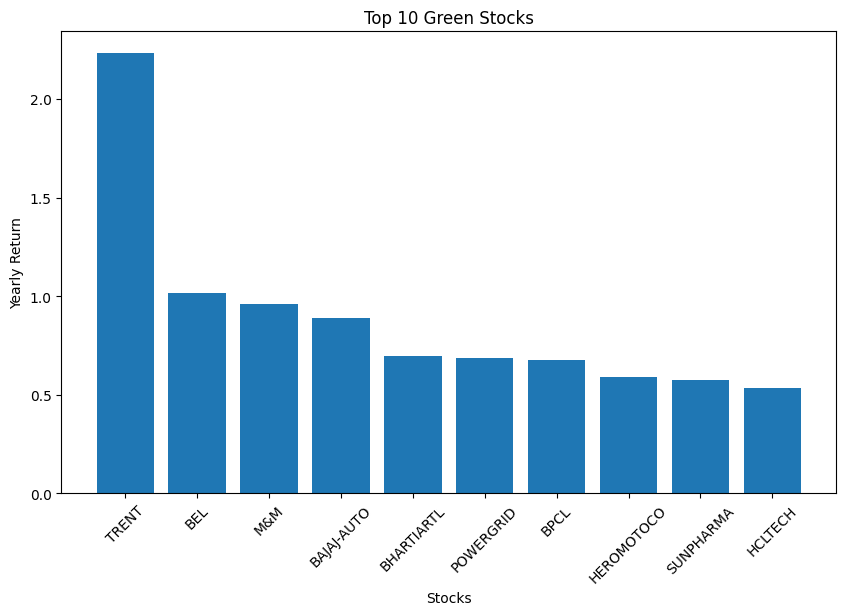

In [42]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_10_greenstocks["Ticker"],
    top_10_greenstocks["Yearly_Return"]
)

plt.xlabel("Stocks")
plt.ylabel("Yearly Return")
plt.title("Top 10 Green Stocks")

plt.xticks(rotation=45)

plt.show()

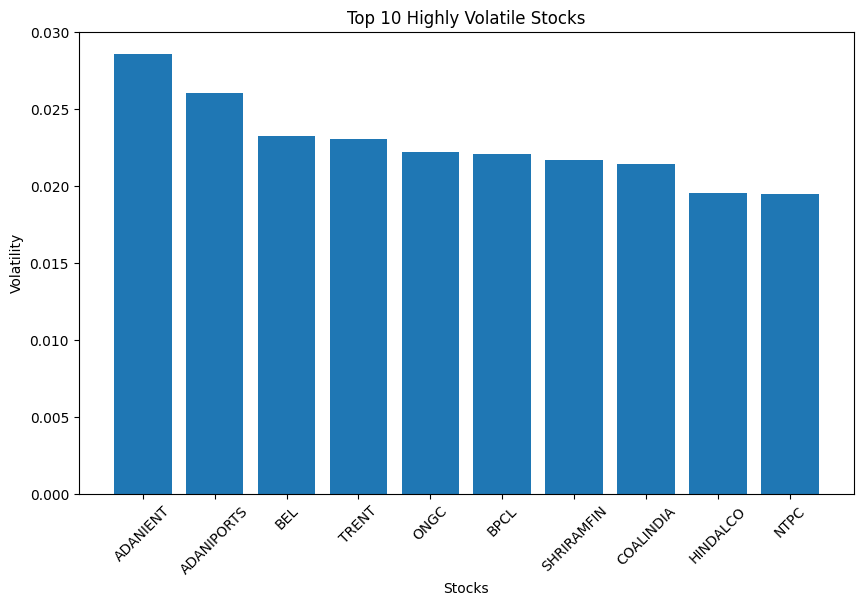

In [43]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_10_volatile["Ticker"],
    top_10_volatile["Volatility"]
)

plt.xlabel("Stocks")
plt.ylabel("Volatility")
plt.title("Top 10 Highly Volatile Stocks")

plt.xticks(rotation=45)
plt.show()

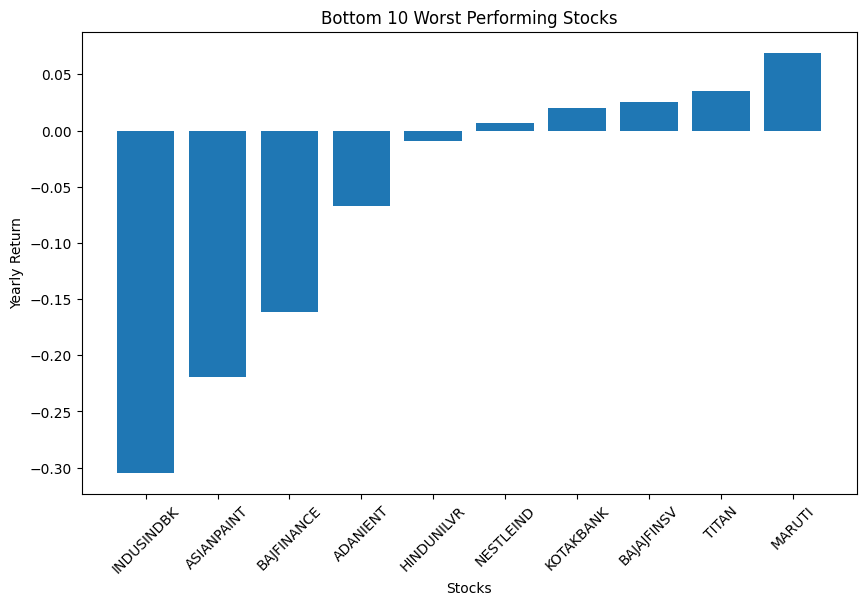

In [44]:
plt.figure(figsize=(10, 6))

plt.bar(
    bottom_10_lossstocks["Ticker"],
    bottom_10_lossstocks["Yearly_Return"]
)

plt.xlabel("Stocks")
plt.ylabel("Yearly Return")
plt.title("Bottom 10 Worst Performing Stocks")

plt.xticks(rotation=45)
plt.show()

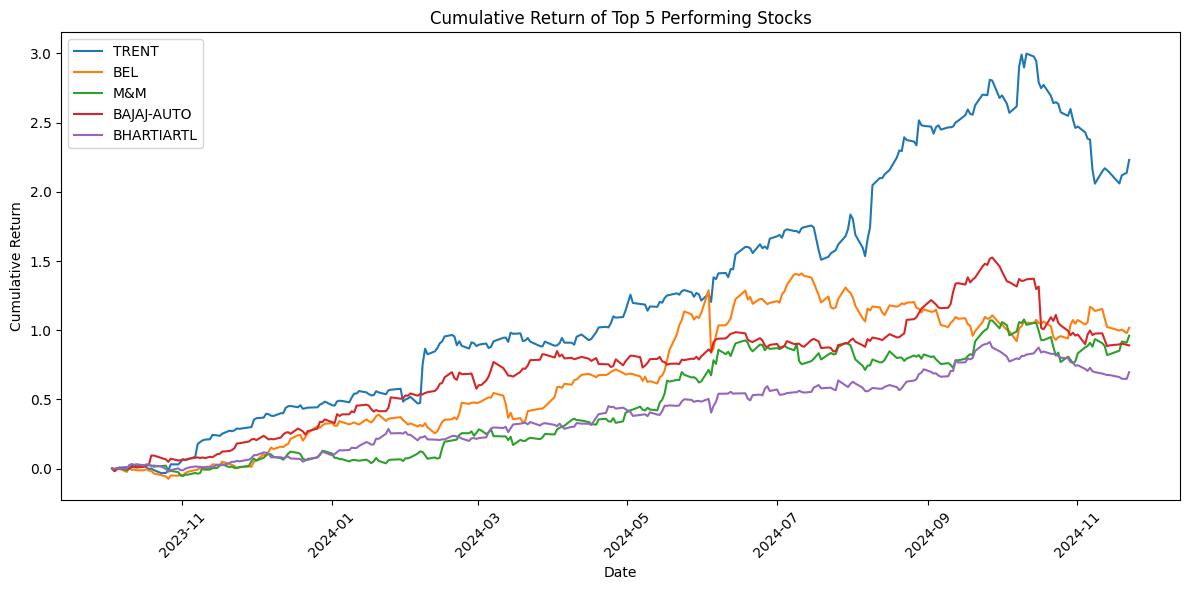

In [45]:
top_5_tickers = top_5_cumulative["Ticker"]

top_5_cumulative_data = cumulative_df[
    cumulative_df["Ticker"].isin(top_5_tickers)
]

plt.figure(figsize=(12, 6))

for ticker in top_5_tickers:

    stock_data = top_5_cumulative_data[
        top_5_cumulative_data["Ticker"] == ticker
    ]

    plt.plot(
        stock_data["date"],
        stock_data["cumulative_return"],
        label=ticker
    )

plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.title("Cumulative Return of Top 5 Performing Stocks")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

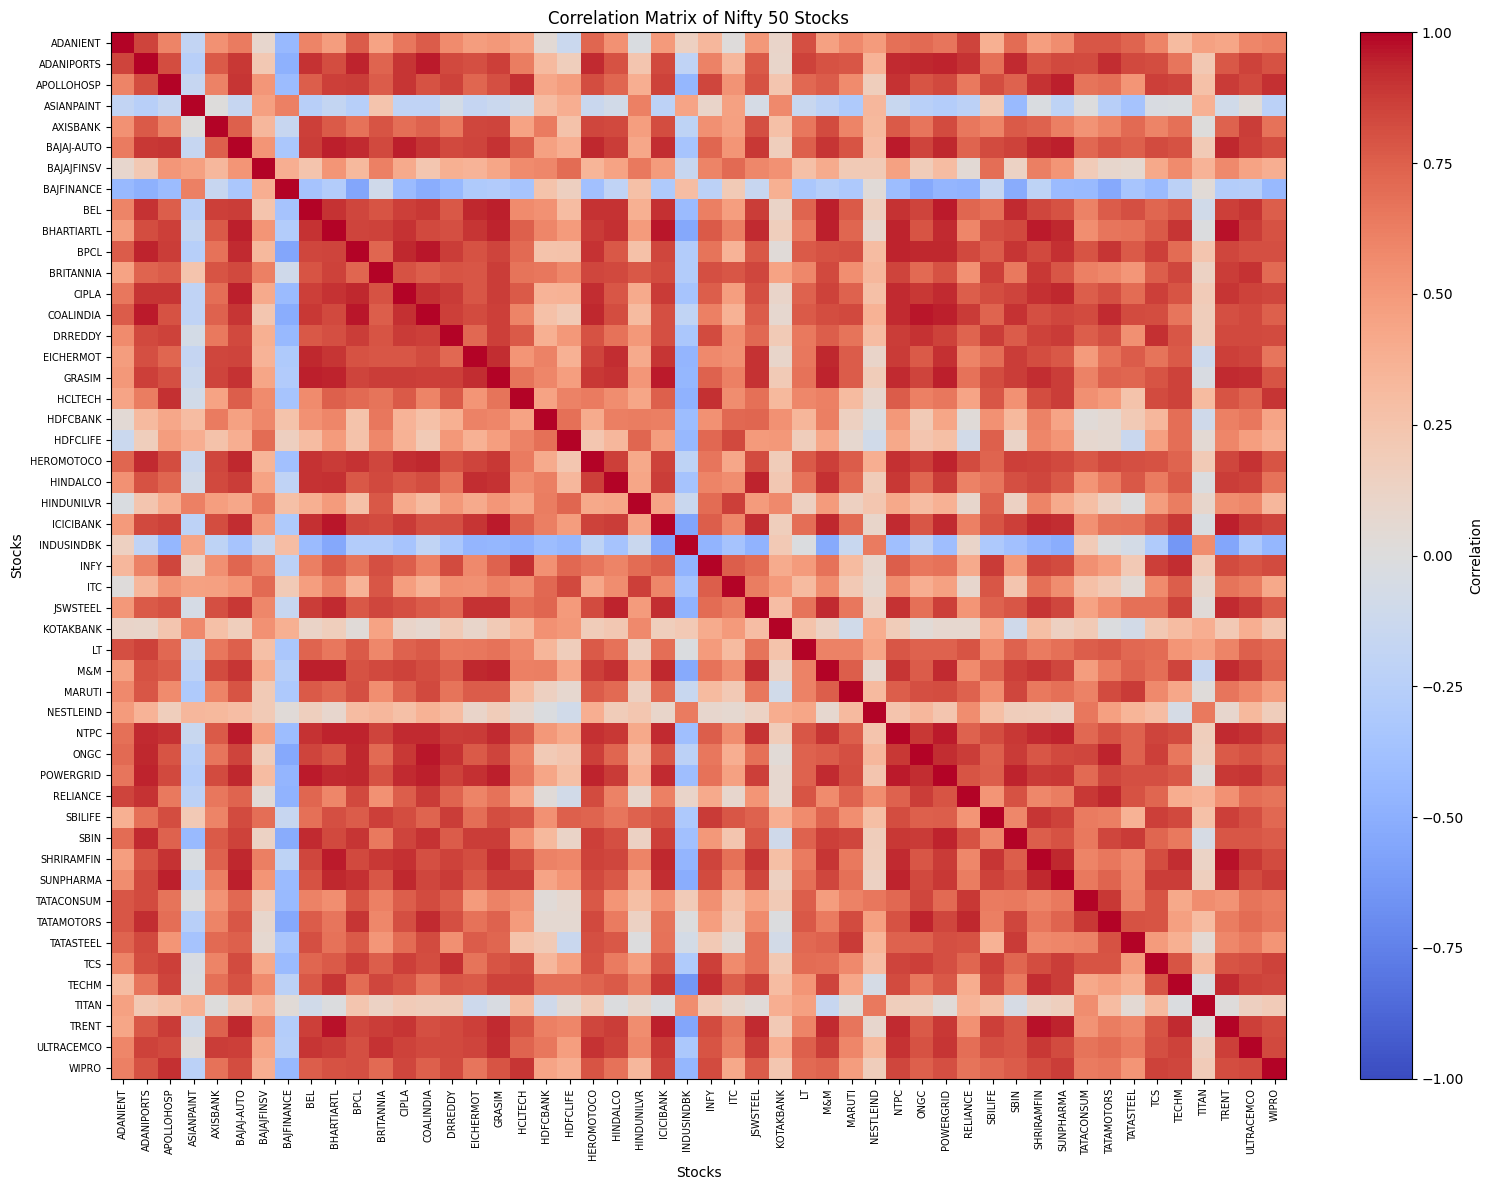

In [46]:


plt.figure(figsize=(16, 12))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index,
    fontsize=7
)

plt.title("Correlation Matrix of Nifty 50 Stocks")
plt.xlabel("Stocks")
plt.ylabel("Stocks")

plt.tight_layout()
plt.show()

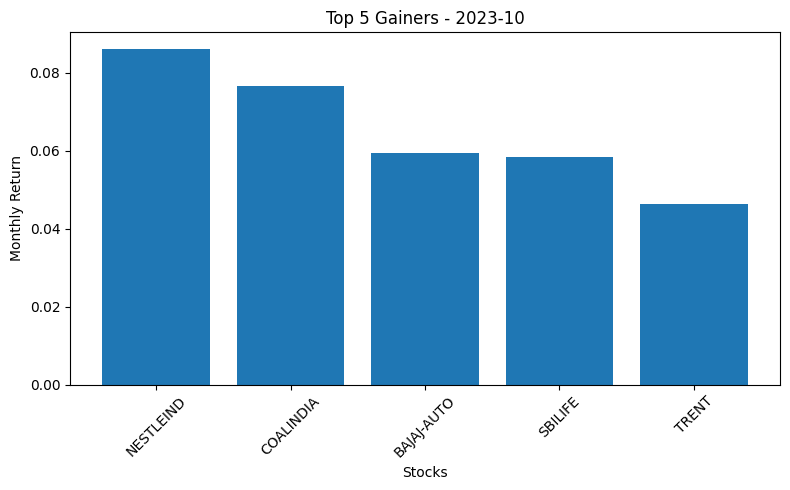

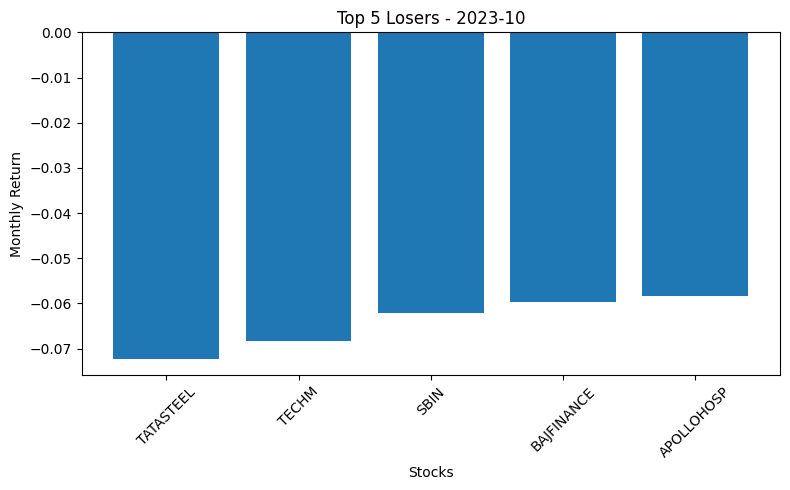

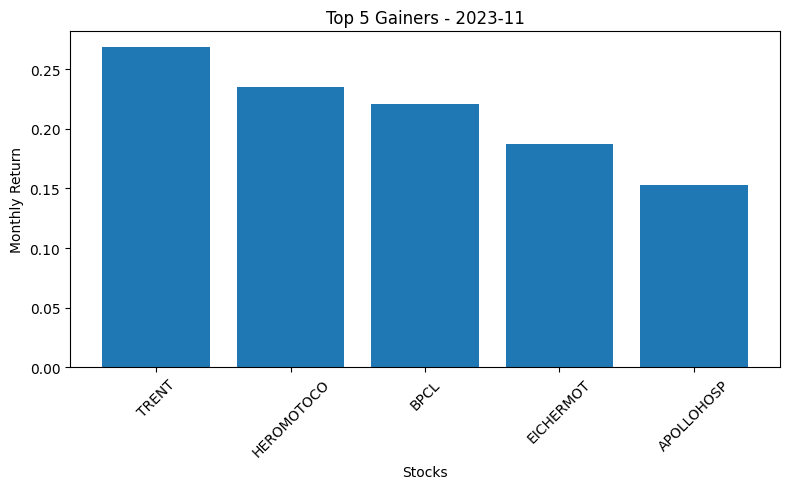

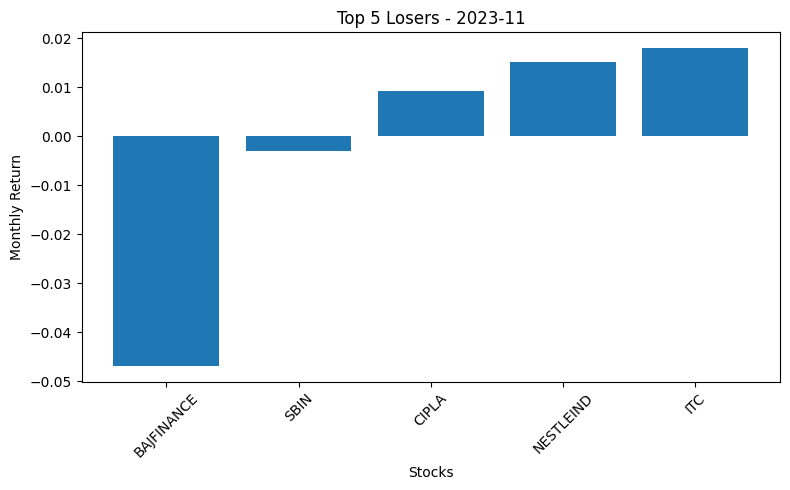

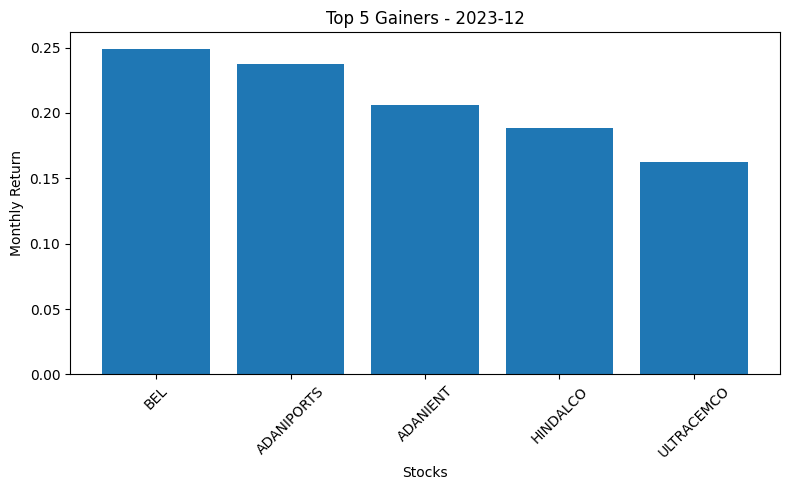

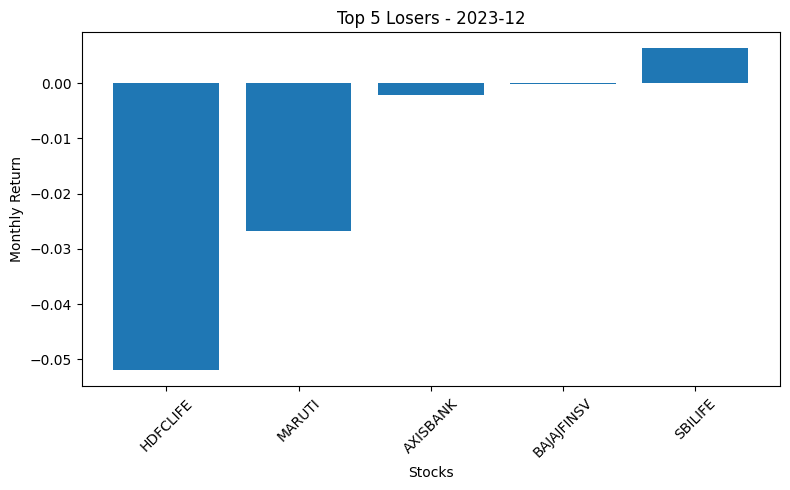

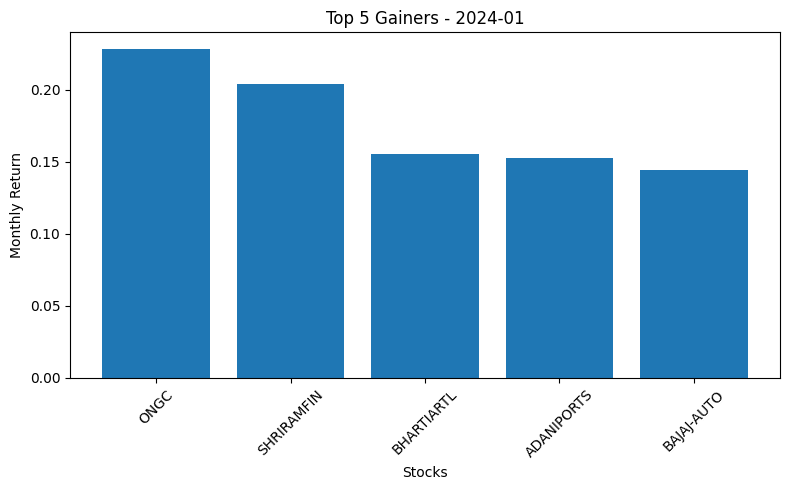

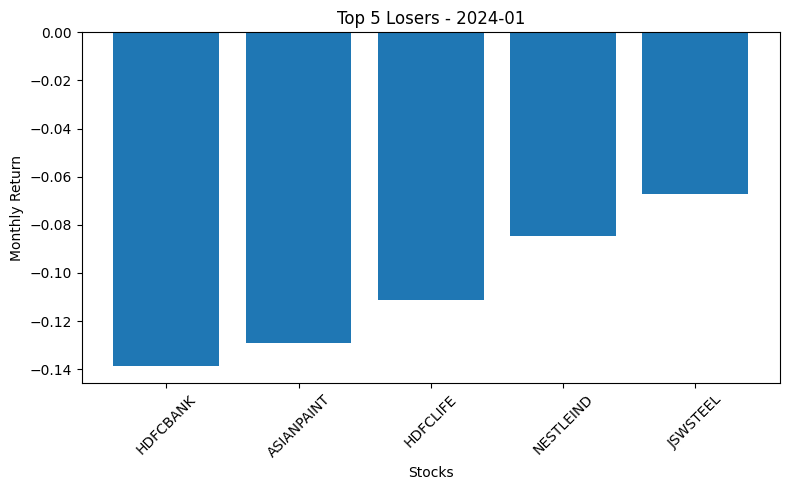

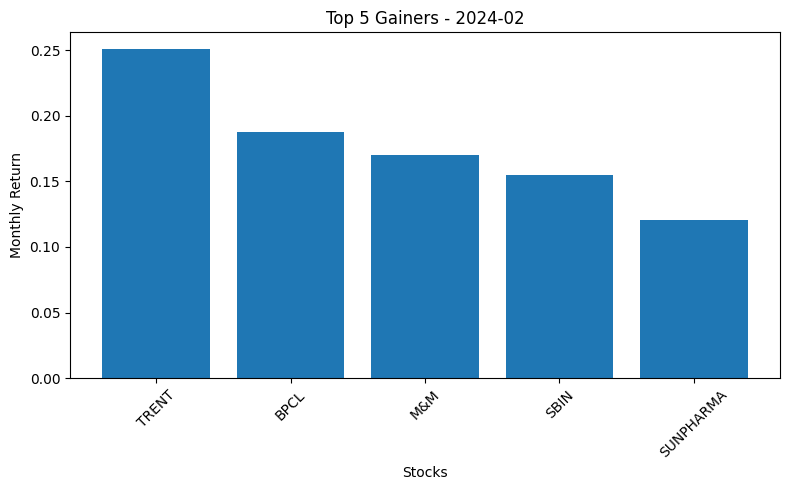

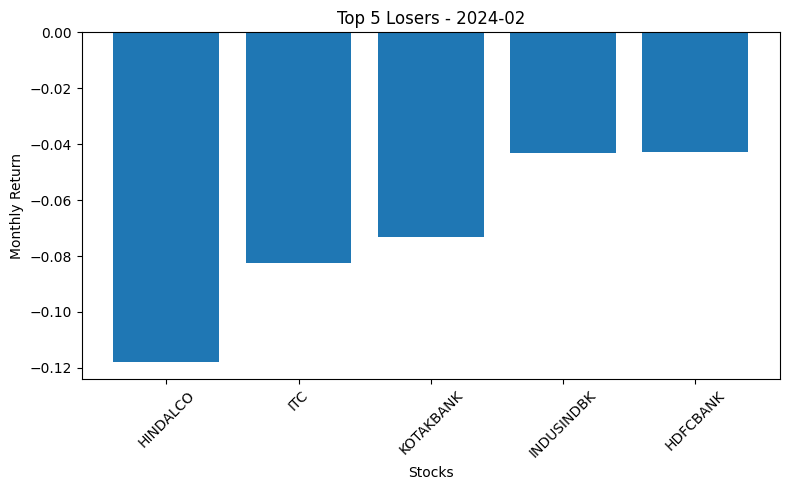

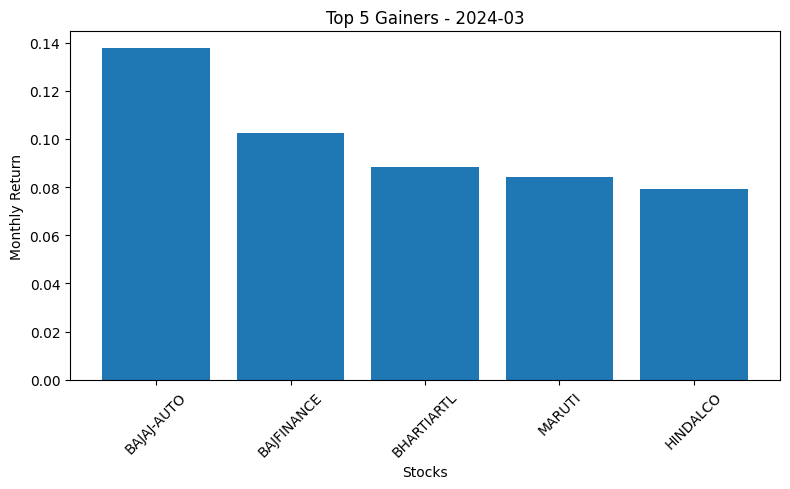

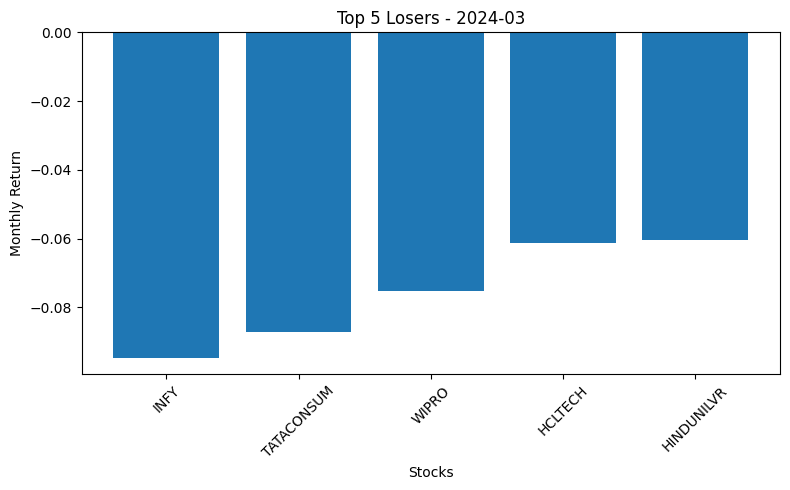

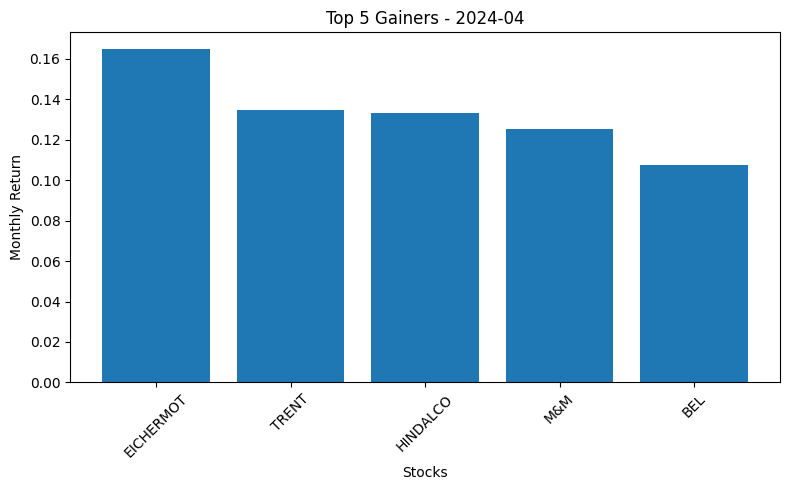

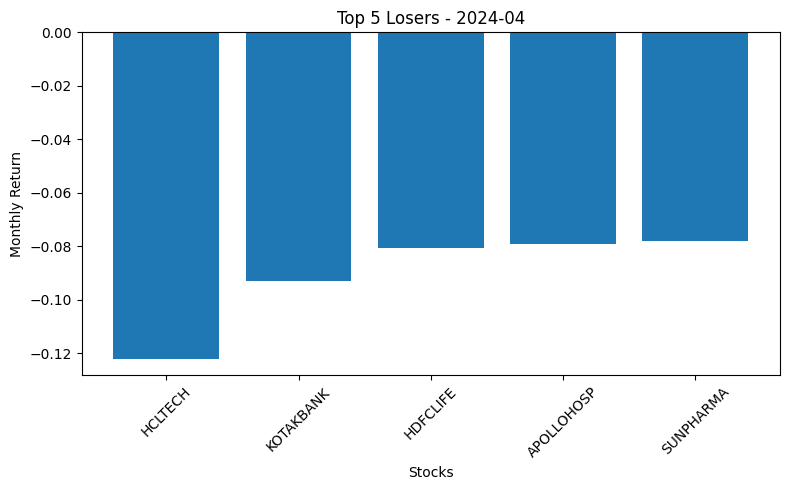

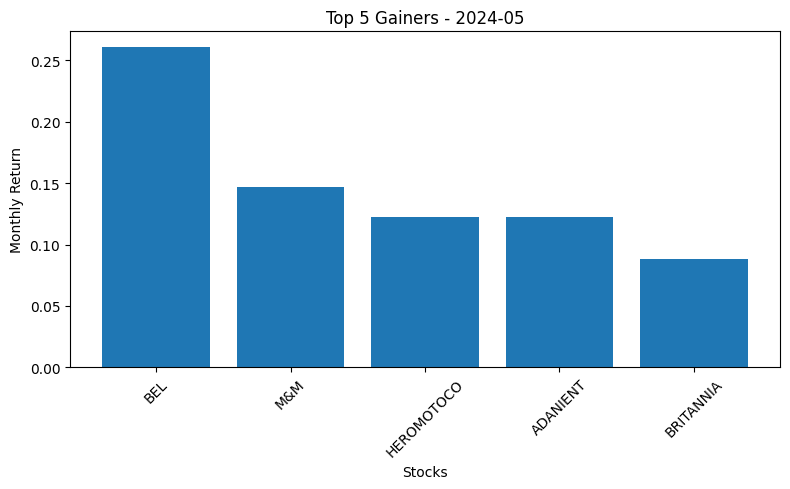

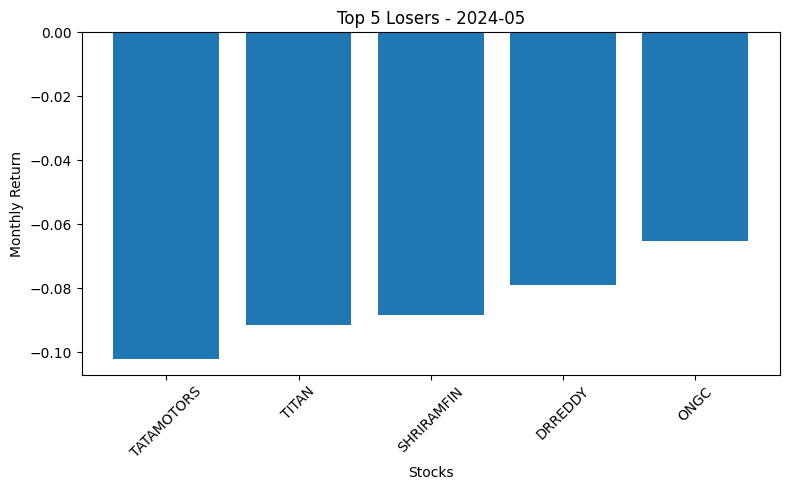

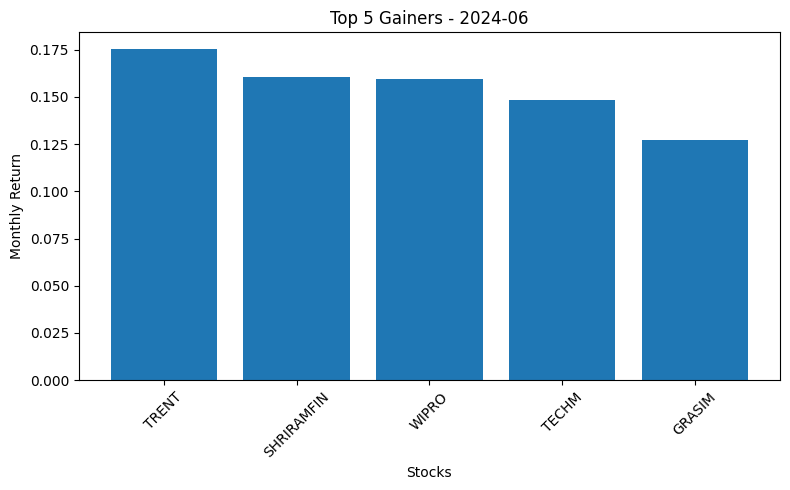

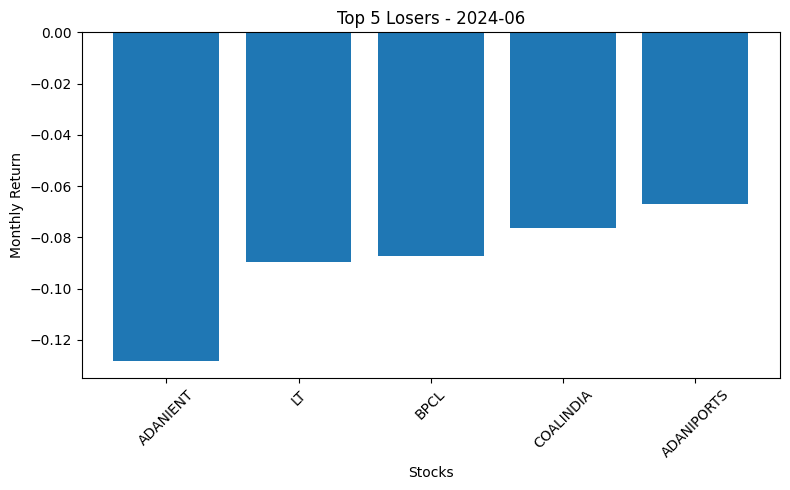

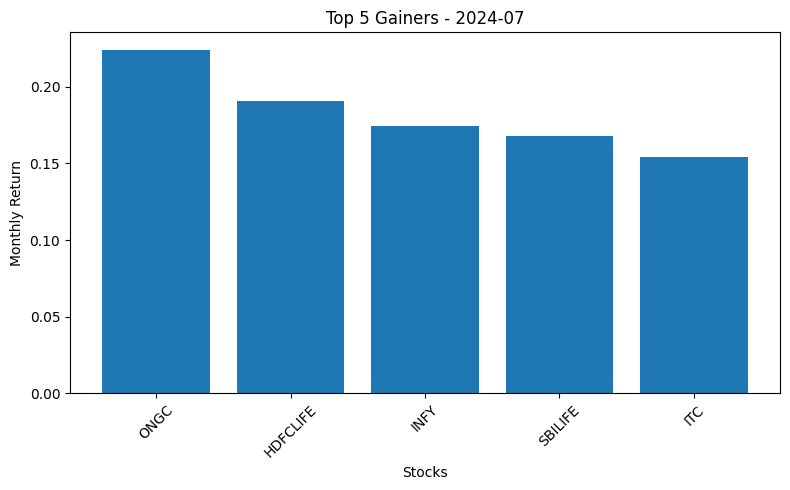

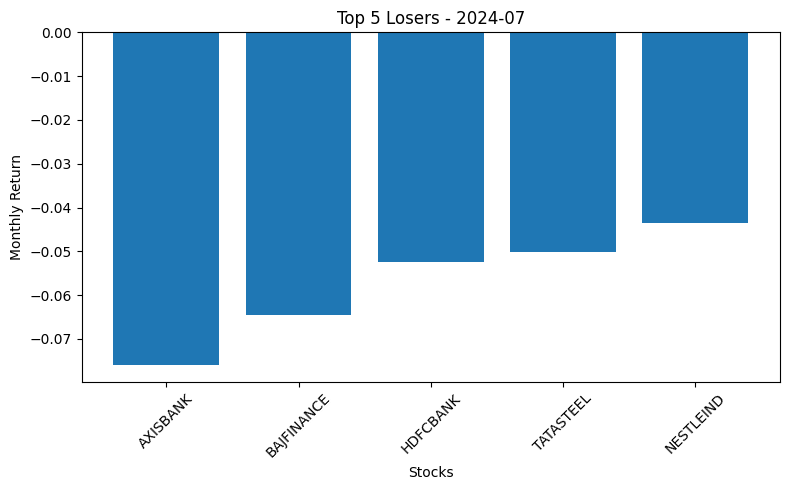

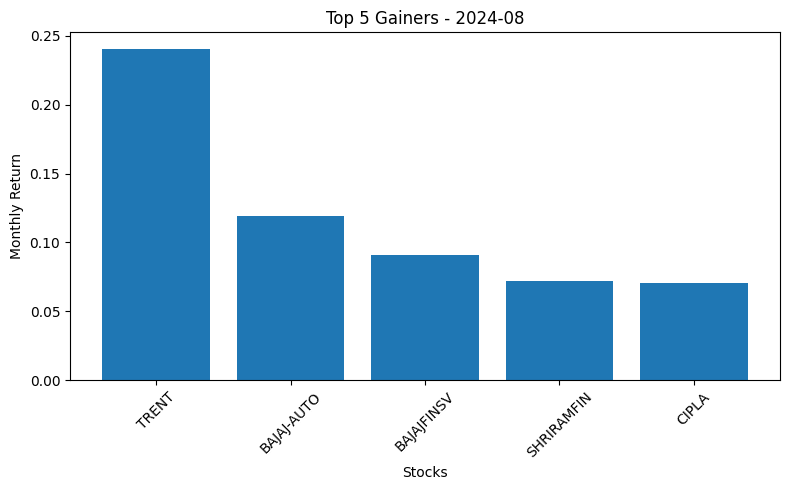

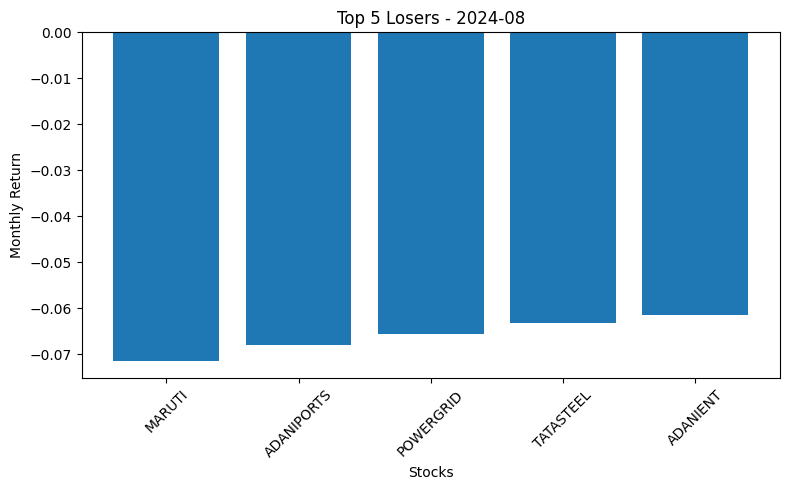

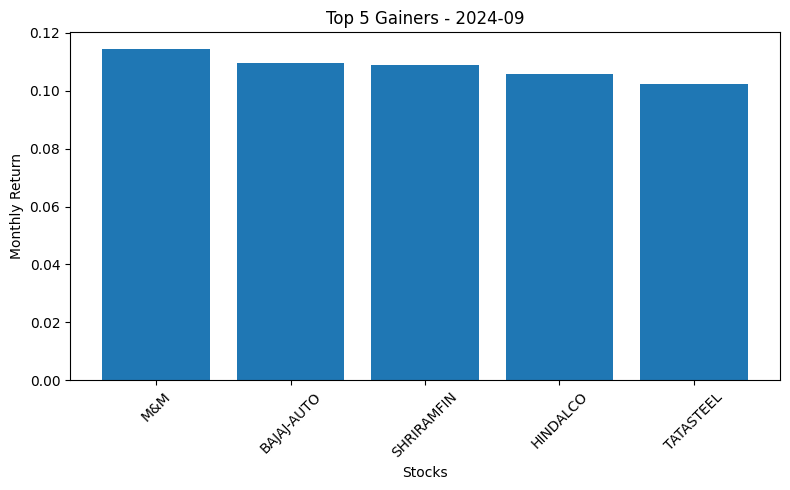

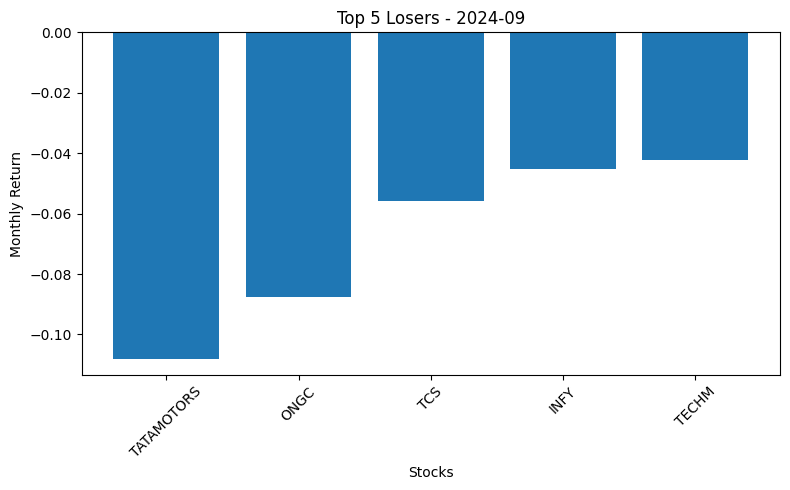

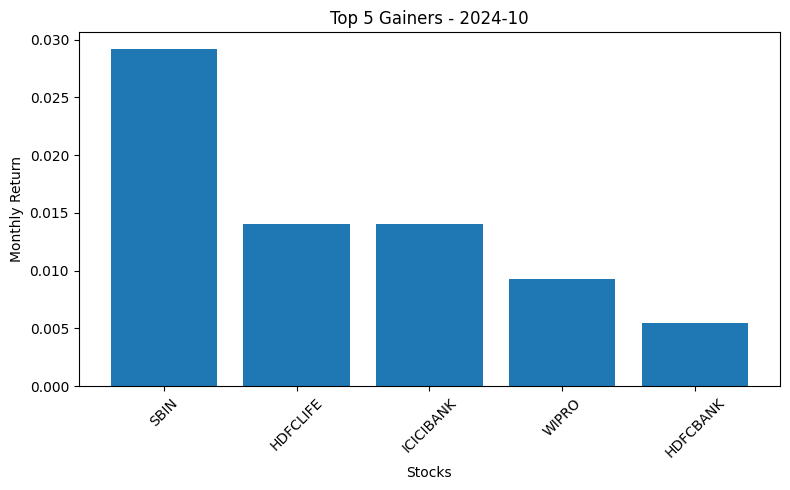

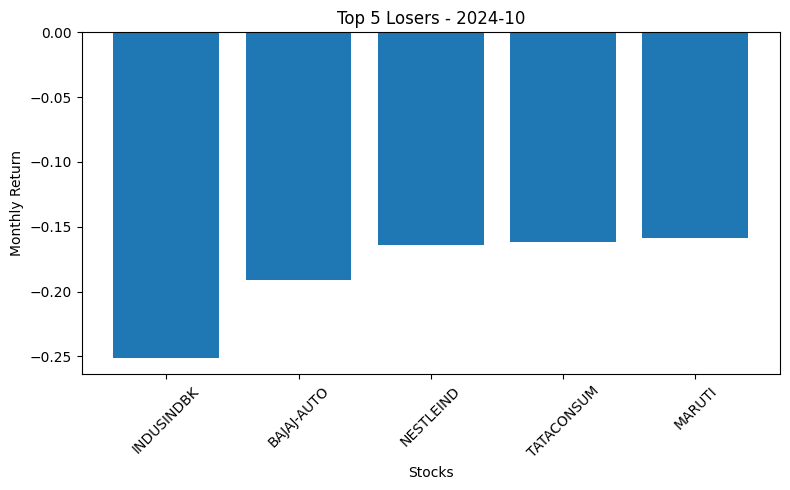

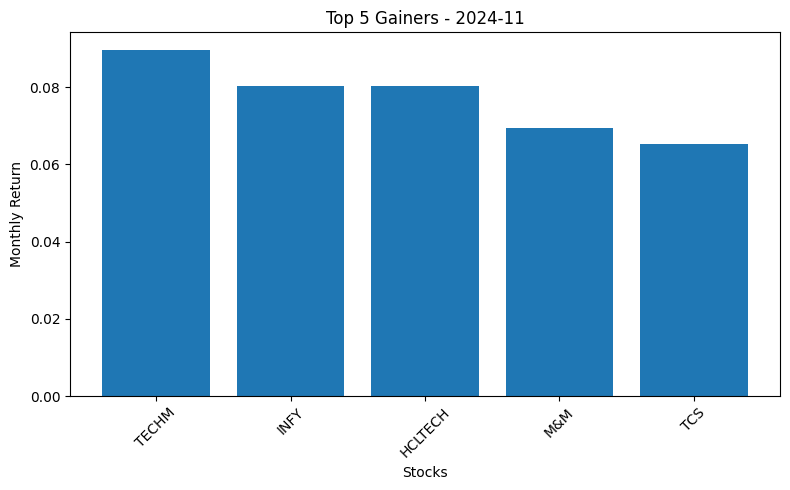

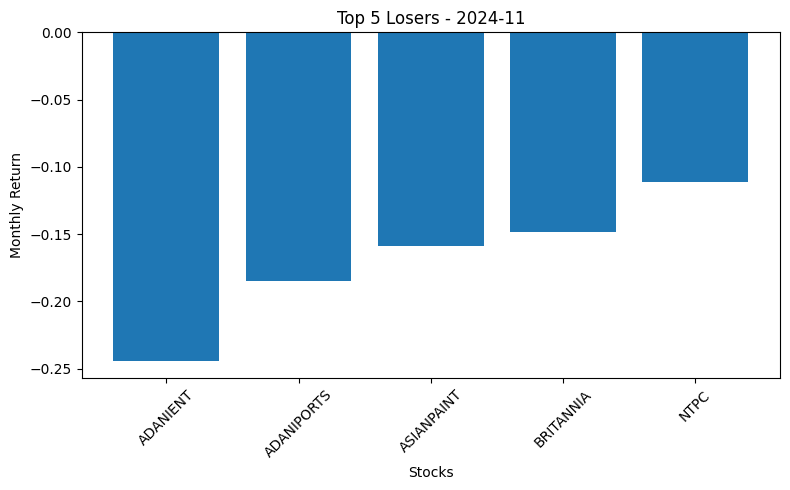

In [47]:
months = sorted(monthly_prices["month"].unique())

for month in months:

    gainers = monthly_top_5_gainers[
        monthly_top_5_gainers["month"] == month
    ]

    losers = monthly_top_5_losers[
        monthly_top_5_losers["month"] == month
    ]

    # TOP 5 GAINERS
    plt.figure(figsize=(8, 5))

    plt.bar(
        gainers["Ticker"],
        gainers["Monthly_Return"]
    )

    plt.xlabel("Stocks")
    plt.ylabel("Monthly Return")
    plt.title(f"Top 5 Gainers - {month}")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


    # TOP 5 LOSERS
    plt.figure(figsize=(8, 5))

    plt.bar(
        losers["Ticker"],
        losers["Monthly_Return"]
    )

    plt.xlabel("Stocks")
    plt.ylabel("Monthly Return")
    plt.title(f"Top 5 Losers - {month}")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [48]:
sector_performance = (
    sector_df
    .groupby("Sector")["Yearly_Return"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.bar(
    sector_performance["Sector"],
    sector_performance["Yearly_Return"]
)

plt.xlabel("Sector")
plt.ylabel("Average Yearly Return")
plt.title("Sector-wise Performance")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'sector_df' is not defined

Missing sectors: 0

SECTOR-WISE PERFORMANCE
                            Sector  Yearly_Return
0                Consumer Services       2.230926
1                    Capital Goods       1.017601
2                Telecommunication       0.695990
3                            Power       0.601841
4   Automobile and Auto Components       0.545265
5           Information Technology       0.382760
6      Oil, Gas & Consumable Fuels       0.378852
7                         Services       0.367272
8           Construction Materials       0.363765
9                       Healthcare       0.324041
10                    Construction       0.172537
11                 Metals & Mining       0.169079
12              Financial Services       0.115043
13      Fast Moving Consumer Goods       0.050579
14               Consumer Durables      -0.092084


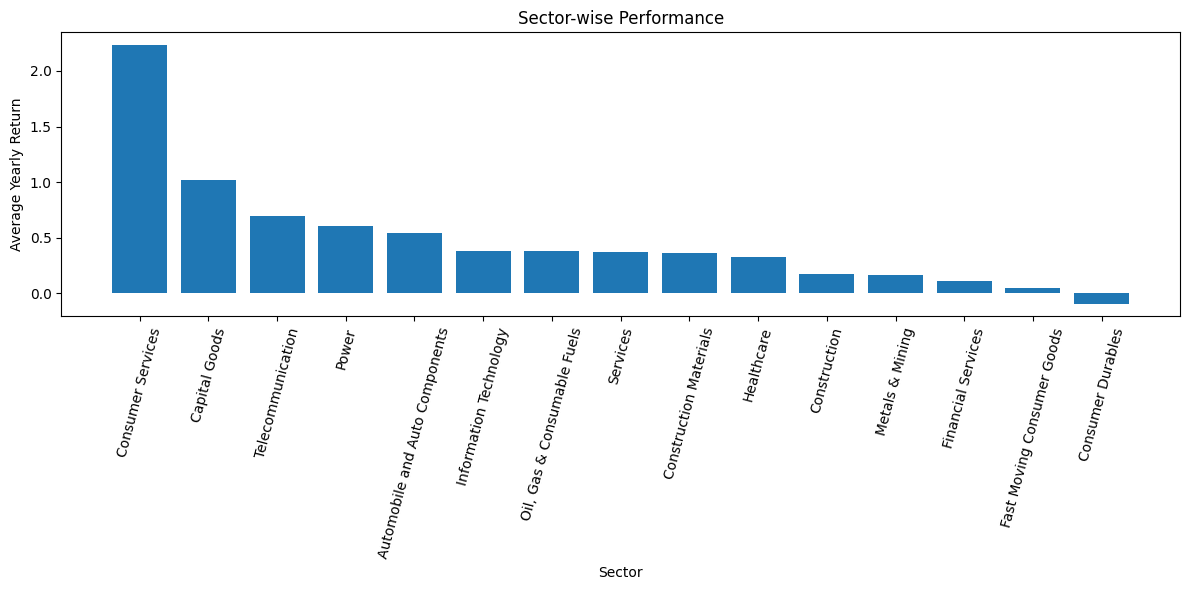

In [ ]:
# ============================================================
# SECTOR-WISE PERFORMANCE
# ============================================================

sector_mapping = {
    "ADANIENT": "Metals & Mining",
    "ADANIPORTS": "Services",
    "APOLLOHOSP": "Healthcare",
    "ASIANPAINT": "Consumer Durables",

    "AXISBANK": "Financial Services",
    "BAJAJ-AUTO": "Automobile and Auto Components",
    "BAJAJFINSV": "Financial Services",
    "BAJFINANCE": "Financial Services",

    "BEL": "Capital Goods",
    "BHARTIARTL": "Telecommunication",
    "BPCL": "Oil, Gas & Consumable Fuels",
    "BRITANNIA": "Fast Moving Consumer Goods",

    "CIPLA": "Healthcare",
    "COALINDIA": "Oil, Gas & Consumable Fuels",
    "DRREDDY": "Healthcare",
    "EICHERMOT": "Automobile and Auto Components",

    "GRASIM": "Construction Materials",
    "HCLTECH": "Information Technology",
    "HDFCBANK": "Financial Services",
    "HDFCLIFE": "Financial Services",

    "HEROMOTOCO": "Automobile and Auto Components",
    "HINDALCO": "Metals & Mining",
    "HINDUNILVR": "Fast Moving Consumer Goods",
    "ICICIBANK": "Financial Services",

    "INDUSINDBK": "Financial Services",
    "INFY": "Information Technology",
    "ITC": "Fast Moving Consumer Goods",
    "JSWSTEEL": "Metals & Mining",

    "KOTAKBANK": "Financial Services",
    "LT": "Construction",
    "M&M": "Automobile and Auto Components",
    "MARUTI": "Automobile and Auto Components",

    "NESTLEIND": "Fast Moving Consumer Goods",
    "NTPC": "Power",
    "ONGC": "Oil, Gas & Consumable Fuels",
    "POWERGRID": "Power",

    "RELIANCE": "Oil, Gas & Consumable Fuels",
    "SBILIFE": "Financial Services",
    "SBIN": "Financial Services",
    "SHRIRAMFIN": "Financial Services",

    "SUNPHARMA": "Healthcare",
    "TATACONSUM": "Fast Moving Consumer Goods",
    "TATAMOTORS": "Automobile and Auto Components",
    "TATASTEEL": "Metals & Mining",

    "TCS": "Information Technology",
    "TECHM": "Information Technology",
    "TITAN": "Consumer Durables",
    "TRENT": "Consumer Services",

    "ULTRACEMCO": "Construction Materials",
    "WIPRO": "Information Technology"
}


# Add sector column
yearly_returns_df["Sector"] = (
    yearly_returns_df["Ticker"].map(sector_mapping)
)


# Safety check — should print 0
print(
    "Missing sectors:",
    yearly_returns_df["Sector"].isna().sum()
)


# Calculate average yearly return for each sector
sector_performance = (
    yearly_returns_df
    .groupby("Sector")["Yearly_Return"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("\nSECTOR-WISE PERFORMANCE")
print(sector_performance)


# ============================================================
# SECTOR-WISE PERFORMANCE BAR CHART
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    sector_performance["Sector"],
    sector_performance["Yearly_Return"]
)

plt.xlabel("Sector")
plt.ylabel("Average Yearly Return")
plt.title("Sector-wise Performance")

plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

In [ ]:
import os

powerbi_folder = r"C:\Users\jana\OneDrive\Documents\project_2_DD\powerbi_data"

os.makedirs(powerbi_folder, exist_ok=True)

powerbi_file = os.path.join(
    powerbi_folder,
    "stock_market_data.csv"
)

combined_df.to_csv(
    powerbi_file,
    index=False
)

print("CSV created successfully!")
print("Location:", powerbi_file)
print("Shape:", combined_df.shape)

CSV created successfully!
Location: C:\Users\jana\OneDrive\Documents\project_2_DD\powerbi_data\stock_market_data.csv
Shape: (14200, 9)


In [ ]:
combined_df

,Ticker,close,date,high,low,month,open,volume,daily_return
0,ADANIENT,2387.25,2023-10-03 05:30:00,2424.90,2372.00,2023-10,2418.00,2019899,NaN
1,ADANIENT,2464.95,2023-10-04 05:30:00,2502.75,2392.25,2023-10,2402.20,2857377,0.032548
2,ADANIENT,2466.35,2023-10-05 05:30:00,2486.50,2446.40,2023-10,2477.95,1132455,0.000568
3,ADANIENT,2478.10,2023-10-06 05:30:00,2514.95,2466.05,2023-10,2466.35,1510035,0.004764
4,ADANIENT,2442.60,2023-10-09 05:30:00,2459.70,2411.30,2023-10,2440.00,1408224,-0.014325
...,...,...,...,...,...,...,...,...,...
14195,WIPRO,566.70,2024-11-14 05:30:00,574.55,564.20,2024-11,568.95,4891760,-0.004042
14196,WIPRO,552.85,2024-11-18 05:30:00,566.70,540.30,2024-11,566.70,7644882,-0.024440
14197,WIPRO,562.00,2024-11-19 05:30:00,569.80,554.70,2024-11,556.00,6459889,0.016551
14198,WIPRO,557.15,2024-11-21 05:30:00,567.60,555.30,2024-11,562.00,5836304,-0.008630


In [ ]:
yearly_returns_df.to_csv(
    r"C:\Users\jana\OneDrive\Documents\project_2_DD\powerbi_data\stock_summary.csv",
    index=False
)

In [ ]:
cumulative_df[
    ["Ticker", "date", "cumulative_return"]
].to_csv(
    r"C:\Users\jana\OneDrive\Documents\project_2_DD\powerbi_data\cumulative_returns.csv",
    index=False
)

In [ ]:
monthly_top_5_gainers.to_csv(
    r"C:\Users\jana\OneDrive\Documents\project_2_DD\powerbi_data\monthly_top_5_gainers.csv",
    index=False
)

In [ ]:
monthly_top_5_losers.to_csv(
    r"C:\Users\jana\OneDrive\Documents\project_2_DD\powerbi_data\monthly_top_5_loosers.csv",
    index=False
)

In [ ]:
correlation_long = (
    correlation_matrix
    .reset_index()
    .melt(
        id_vars="Ticker",
        var_name="Ticker_2",
        value_name="Correlation"
    )
)

print(correlation_long.head())
print(correlation_long.shape)

       Ticker  Ticker_2  Correlation
0    ADANIENT  ADANIENT     1.000000
1  ADANIPORTS  ADANIENT     0.845806
2  APOLLOHOSP  ADANIENT     0.594807
3  ASIANPAINT  ADANIENT    -0.186479
4    AXISBANK  ADANIENT     0.537048
(2500, 3)


In [ ]:
correlation_long.to_csv(
    r"C:\Users\jana\OneDrive\Documents\project_2_DD\powerbi_data\correlation_long.csv",
    index=False
)

# SQL CONNECTION

In [58]:
import mysql.connector

mydb = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root"
)

mycursor = mydb.cursor()

mycursor.execute("CREATE DATABASE IF NOT EXISTS stock_analysis")

print("Database created successfully")

Database created successfully


In [59]:
import mysql.connector

mydb = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="stock_analysis"
)

mycursor = mydb.cursor()

print("MySQL Connected Successfully")

MySQL Connected Successfully


In [61]:
mycursor.execute("""
CREATE TABLE IF NOT EXISTS stock_data (
    Ticker VARCHAR(20),
    close DOUBLE,
    date DATETIME,
    high DOUBLE,
    low DOUBLE,
    month VARCHAR(10),
    open DOUBLE,
    volume BIGINT,
    daily_return DOUBLE NULL
)
""")

mydb.commit()

print("Table created successfully")


Table created successfully


In [62]:


df["date"] = pd.to_datetime(df["date"])

df = df.where(pd.notnull(df), None)

insert_query = """
INSERT INTO stock_data
(Ticker, close, date, high, low, month, open, volume, daily_return)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

data = [
    (
        row["Ticker"],
        row["close"],
        row["date"].to_pydatetime(),
        row["high"],
        row["low"],
        row["month"],
        row["open"],
        int(row["volume"]),
        None if pd.isna(row["daily_return"]) else row["daily_return"]
    )
    for _, row in df.iterrows()
]

mycursor.executemany(insert_query, data)

mydb.commit()

print("Data inserted successfully")
print("Rows inserted:", mycursor.rowcount)

Data inserted successfully
Rows inserted: 14200


In [63]:
mycursor.execute("SELECT COUNT(*) FROM stock_data")

result = mycursor.fetchone()

print("Total rows in MySQL:", result[0])

Total rows in MySQL: 14200
